# Numpy-Statistics Project

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 

In [2]:
df = pd.read_csv("student_scores.csv") # using pandas library
df

,student_id,method,score
0,1,Traditional,72.0
1,2,Traditional,66.9
2,3,Traditional,73.2
3,4,Traditional,80.2
4,5,Traditional,66.1
...,...,...,...
115,116,Blended,79.1
116,117,Blended,76.8
117,118,Blended,68.8
118,119,Blended,85.0


## measure of central tendency

In [3]:
m=np.mean(df["score"]) #using numpy library
print("population mean:",m)
med=np.median(df["score"])
print("population median:",med)
mo=df["score"].mode()[0]
print("highest frequency:",mo)

population mean: 71.68583333333332
population median: 72.55
highest frequency: 63.2


In [4]:
med=df["score"].median() #using pandas library
print(med)

72.55


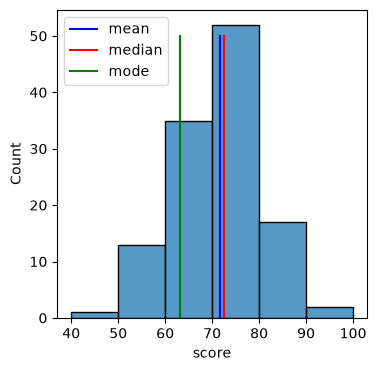

In [5]:
plt.figure(figsize=(4,4))
sns.histplot(x="score",data=df,bins=[i for i in range(40,101,10)])
plt.plot([m for i in range(0,51)],[i for i in range (0,51)],c="blue",label="mean")
plt.plot([med for i in range(0,51)],[i for i in range(0,51)],c="red",label="median")
plt.plot([mo for i in range(0,51)],[i for i in range(0,51)],c="green",label="mode")
plt.legend()

plt.show() 

## measure of dispersion

### range 

In [6]:
## range= min and max of data to know the spreadness of data using numpy library
minscore=np.min(df["score"])
print("minimum score:",minscore)
maxscore=np.max(df["score"])
print("maximum score:",maxscore)
range1=maxscore-minscore
print("range:",range1)

minimum score: 48.4
maximum score: 94.2
range: 45.800000000000004


### variance

In [7]:
# using numpy
samp_var=np.var(df["score"],ddof=1) 
print("sample variance is:", samp_var)

pop_var=np.var(df["score"],ddof=0)
print("population variance is:", pop_var)

sample variance is: 75.39315896358542
population variance is: 74.76488263888888


In [8]:
# using pandas
series=pd.Series(df["score"])
sam_var=series.var(ddof=1)
print("sample variance", sam_var)

popvar=series.var(ddof=0)
print("population variance", popvar)

# using scipy
samp=stats.tvar(df["score"]) # by default sample variance if no ddof is given
print("sample variance", samp)

pop=stats.tvar(df["score"])
print("population variance",pop)

sample variance 75.39315896358542
population variance 74.76488263888888
sample variance 75.39315896358542
population variance 75.39315896358542


## standard deviation

In [9]:
import math

In [10]:
# using numpy
samstd=np.std(df["score"],ddof=1)
print("sample std deviation", samstd)
popstd=np.std(df["score"],ddof=0)
print("population std dev",popstd)

sample std deviation 8.682923411132073
population std dev 8.646668875288846


In [11]:
# usind pandas----- series.std(), series.std(ddof=0)
# using scipy
sam=math.sqrt(stats.tvar(df["score"]))
print("sample std dev:",sam)
pop1=math.sqrt(stats.tvar(df["score"],ddof=0))
print("population std dev",pop1)

sample std dev: 8.682923411132073
population std dev 8.646668875288846


## data representation

Skewness calculated is: -0.26911098294031316
right-sided, negatively skewed


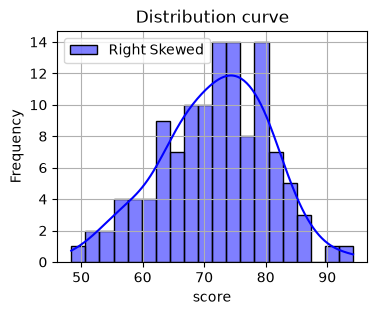

In [12]:
#Skewness distribution
sk=df["score"].skew()
print("Skewness calculated is:",sk)
if sk>0:
    print(", left-sided, positively skewed")
elif sk<0:
    print("right-sided, negatively skewed")
else:
    print("symmetric")
    
# Distribution Curve of dataset
plt.figure(figsize=(4,3))
sns.histplot(df["score"],bins=20,kde=True, color="blue", label='Right Skewed') # KDE- kernel density estimste
plt.title("Distribution curve")
plt.grid(True)
plt.legend()
plt.ylabel("Frequency")


plt.show()

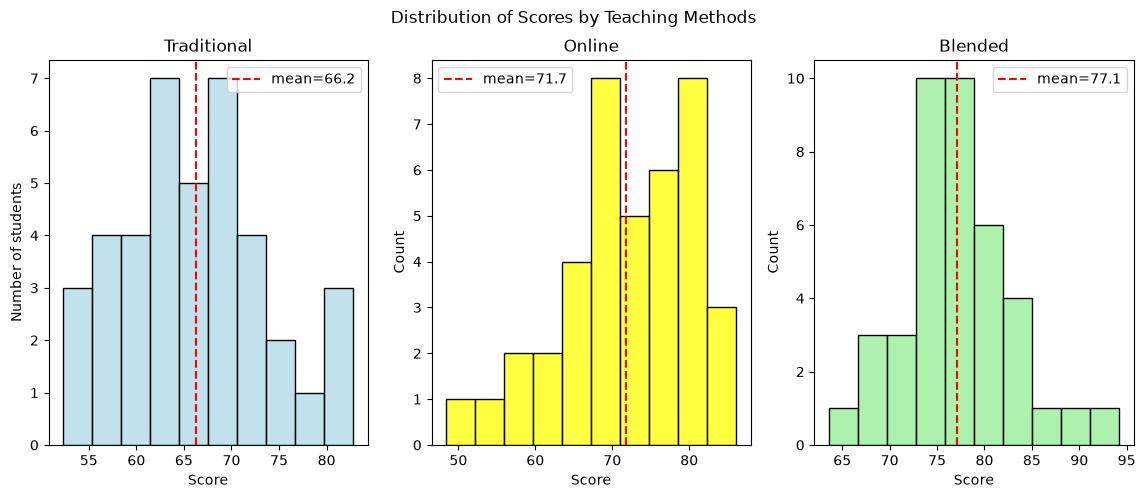

In [13]:
methods = ["Traditional", "Online", "Blended"]
colors = ["lightblue", "yellow", "lightgreen"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle("Distribution of Scores by Teaching Methods")
for method, color, i in zip(methods, colors, axes):
    scores = df[df["method"] == method]["score"]
    mean_score = scores.mean()
    sns.histplot(scores,bins=10, color=color,edgecolor="black", ax=i)
    i.axvline(mean_score, color="red", linestyle="--", label=f"mean={mean_score:.1f}")
    i.set_title(method)
    i.set_xlabel("Score")
    i.legend()
axes[0].set_ylabel("Number of students")


plt.show()

## ANOVA Test

#### null hypothesis(H0)= teaching methods can not affect the scores
#### alternate hypothesis(H1)= teaching methods can affect the scores

In [14]:
# why ANOVA??--- Because of more groups in the comparison and standard variation is not known.

In [15]:
grouped_scores=df.groupby("method")["score"] # grouping the scores acc to the teaching methods
statistics=grouped_scores.agg(["count","mean","var","std"]) # calculating the descriptive stastics measures.
print(statistics)

             count     mean        var       std
method                                          
Blended         40  77.0775  36.291019  6.024203
Online          40  71.7350  75.489513  8.688470
Traditional     40  66.2450  58.085615  7.621392


In [16]:
# extracting the groups 
traditional=grouped_scores.get_group("Traditional")
blended=grouped_scores.get_group("Blended")
online=grouped_scores.get_group("Online")

In [17]:
from scipy.stats import f_oneway,f

f_stat, p_value= f_oneway(traditional, online, blended)
print("F static value is:",f_stat)
print("P-value is:", p_value)

alpha= 0.05

if p_value>= 0.05:
    print("Fails to reject null hypothesis, No significant mean differences in the sample")
else:
    print("Rejects the null hypothesis, atleast one mean difference is found in the sample.") 

F static value is: 20.725196298035414
P-value is: 1.9729392653581127e-08
Rejects the null hypothesis, atleast one mean difference is found in the sample.


## ANOVA visualization

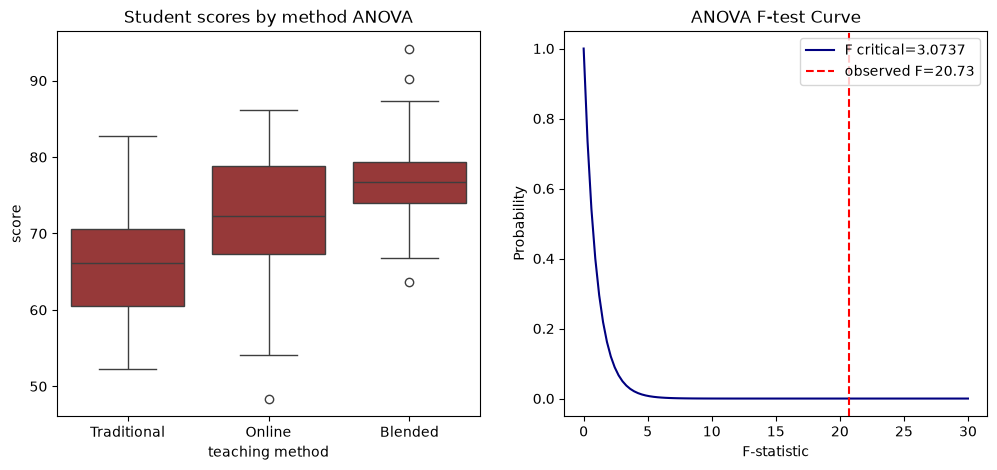

In [18]:
methods = ["traditional","blended","online"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="method", y="score", color="brown", ax=axes[0])
axes[0].set_title("Student scores by method ANOVA")
axes[0].set_xlabel("teaching method")
axes[0].set_ylabel("score")

#calculating the probability density in the data
df_between = 2      
df_within = (len(df)-3)

#setting the axes
x= np.linspace(0,30,100) #evenly placed 100 values in the rang mentiond
y=f.pdf(x,df_between,df_within) #using 'f' to draw the curve

f_crit=3.0737
axes[1].plot(x,y,color="navy", label=f"F critical={f_crit}")
axes[1].axvline(f_stat, color="red", linestyle="--", label=f"observed F={f_stat:.2f}") 
axes[1].set_title("ANOVA F-test Curve")
axes[1].set_xlabel("F-statistic")
axes[1].set_ylabel("Probability")
axes[1].legend()

plt.show()